Object 1: Square
Object 2: Hexagon
Object 3: Square
Object 4: Square
Object 5: Triangle

Number of Objects = 5
Square Object = 3
Hexagon Object = 1
Triangle Object = 1


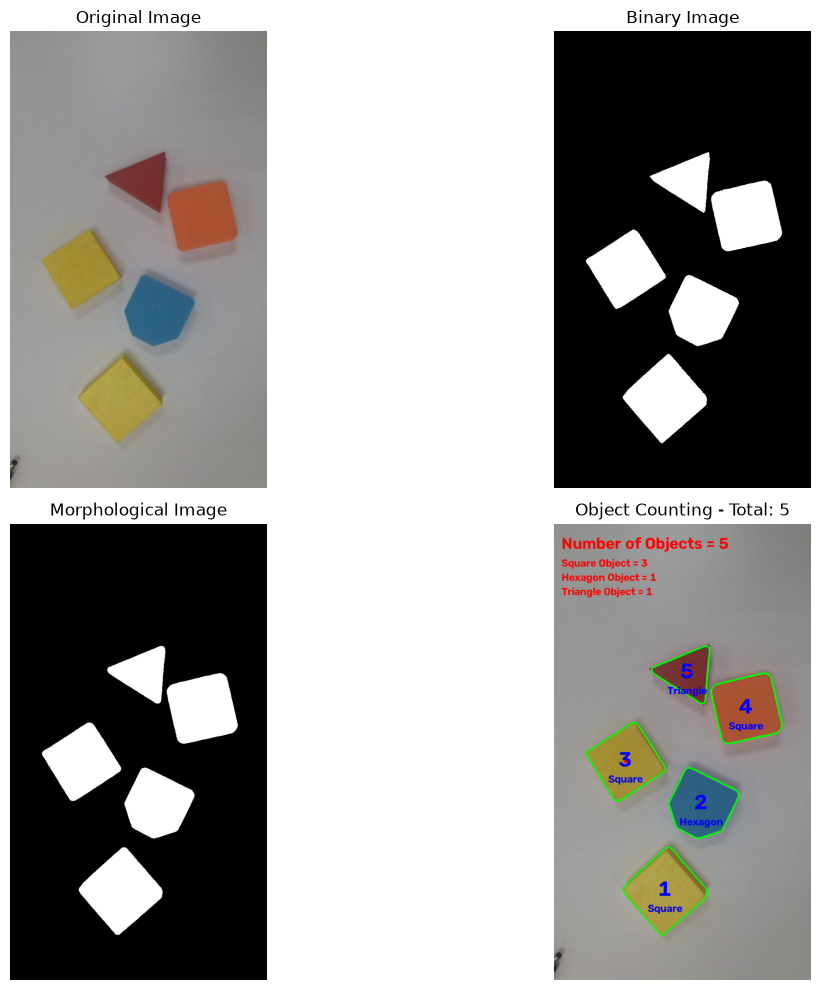

In [39]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

IMAGE_PATH = "object counting 5.jpg"
MIN_AREA = 5000


def classify_shape(contour):
    """Classify a contour as a polygon or circle."""
    perimeter = cv2.arcLength(contour, True)
    approx = cv2.approxPolyDP(contour, 0.02 * perimeter, True)
    vertices = len(approx)

    shape_names = {
        3: "Triangle",
        4: "Quadrilateral",
        5: "Pentagon",
        6: "Hexagon",
        7: "Heptagon",
        8: "Octagon",
    }

    if vertices in shape_names:
        name = shape_names[vertices]

        # Separate square and rectangle
        if vertices == 4:
            x, y, w, h = cv2.boundingRect(approx)
            aspect_ratio = w / float(h)

            if 0.90 <= aspect_ratio <= 1.10:
                name = "Square"
            else:
                name = "Rectangle"

        return name

    if vertices > 8:
        area = cv2.contourArea(contour)

        circularity = (
            4 * np.pi * area / (perimeter ** 2)
            if perimeter > 0 else 0
        )

        return "Circle" if circularity > 0.8 else f"{vertices}-gon"

    return f"{vertices}-gon"


def main():

    image = cv2.imread(IMAGE_PATH)

    if image is None:
        print("ERROR: Image could not be loaded.")
        print("Check the image filename and location.")
        return

    result = image.copy()

    # ==================================================
    # PREPROCESSING
    # ==================================================

    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    saturation = hsv[:, :, 1]

    saturation = cv2.GaussianBlur(
        saturation,
        (5, 5),
        0
    )

    # Thresholding
    _, binary = cv2.threshold(
        saturation,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Morphological closing
    close_kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (11, 11)
    )

    closing = cv2.morphologyEx(
        binary,
        cv2.MORPH_CLOSE,
        close_kernel
    )

    # Morphological opening
    open_kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (19, 19)
    )

    opening = cv2.morphologyEx(
        closing,
        cv2.MORPH_OPEN,
        open_kernel
    )

    # ==================================================
    # CONTOUR DETECTION
    # ==================================================

    contours, hierarchy = cv2.findContours(
        opening,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    # Total object count
    count = 0

    # Dictionary for shape counting
    shape_counts = {}

    # ==================================================
    # OBJECT DETECTION
    # ==================================================

    for contour in contours:

        area = cv2.contourArea(contour)

        # Ignore small noise
        if area > MIN_AREA:

            count += 1

            # Determine shape
            shape_name = classify_shape(contour)

            # ------------------------------------------
            # COUNT EACH SHAPE
            # ------------------------------------------

            if shape_name in shape_counts:
                shape_counts[shape_name] += 1
            else:
                shape_counts[shape_name] = 1

            # ------------------------------------------
            # DRAW CONTOUR
            # ------------------------------------------

            cv2.drawContours(
                result,
                [contour],
                -1,
                (0, 255, 0),
                3
            )

            # ------------------------------------------
            # FIND CENTER
            # ------------------------------------------

            M = cv2.moments(contour)

            if M["m00"] != 0:

                cx = int(M["m10"] / M["m00"])
                cy = int(M["m01"] / M["m00"])

                # Center point
                cv2.circle(
                    result,
                    (cx, cy),
                    5,
                    (0, 0, 255),
                    -1
                )

                # Object number
                cv2.putText(
                    result,
                    str(count),
                    (cx - 20, cy + 15),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    2.0,
                    (255, 0, 0),
                    4
                )

                # Shape name
                label_size, _ = cv2.getTextSize(
                    shape_name,
                    cv2.FONT_HERSHEY_SIMPLEX,
                    1.0,
                    3
                )

                cv2.putText(
                    result,
                    shape_name,
                    (
                        cx - label_size[0] // 2,
                        cy + 60
                    ),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    1.0,
                    (255, 0, 0),
                    3
                )

            print(f"Object {count}: {shape_name}")

    # ==================================================
    # PRINT TOTAL AND SHAPE COUNTS
    # ==================================================

    print("\n==============================")
    print(f"Number of Objects = {count}")
    print("==============================")

    for shape, number in shape_counts.items():
        print(f"{shape} Object = {number}")

    # ==================================================
    # DISPLAY TOTAL COUNT ON IMAGE
    # ==================================================

    text = f"Number of Objects = {count}"

    cv2.putText(
        result,
        text,
        (20, 70),
        cv2.FONT_HERSHEY_SIMPLEX,
        1.5,
        (0, 0, 255),
        3
    )

    # ==================================================
    # DISPLAY SHAPE COUNTS ON IMAGE
    # ==================================================

    y_position = 120

    for shape, number in shape_counts.items():

        text = f"{shape} Object = {number}"

        cv2.putText(
            result,
            text,
            (20, y_position),
            cv2.FONT_HERSHEY_SIMPLEX,
            1.0,
            (0, 0, 255),
            2
        )

        y_position += 40

    # ==================================================
    # MATPLOTLIB DISPLAY
    # ==================================================

    # OpenCV BGR -> Matplotlib RGB
    image_rgb = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    result_rgb = cv2.cvtColor(
        result,
        cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(14, 10))

    # ------------------------------------------
    # Original
    # ------------------------------------------

    plt.subplot(2, 2, 1)

    plt.imshow(image_rgb)

    plt.title("Original Image")

    plt.axis("off")

    # ------------------------------------------
    # Binary
    # ------------------------------------------

    plt.subplot(2, 2, 2)

    plt.imshow(
        binary,
        cmap="gray"
    )

    plt.title("Binary Image")

    plt.axis("off")

    # ------------------------------------------
    # Morphological
    # ------------------------------------------

    plt.subplot(2, 2, 3)

    plt.imshow(
        opening,
        cmap="gray"
    )

    plt.title("Morphological Image")

    plt.axis("off")

    # ------------------------------------------
    # Result
    # ------------------------------------------

    plt.subplot(2, 2, 4)

    plt.imshow(result_rgb)

    plt.title(
        f"Object Counting - Total: {count}"
    )

    plt.axis("off")

    plt.tight_layout()

    plt.show()


if __name__ == "__main__":
    main()